In [ ]:
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from pathlib import Path
from collections import Counter
from matplotlib import colors
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from matplotlib import colors

In [ ]:
import re
import time
import os
import hashlib
import numpy as np
import pandas as pd
import torch as to
import matplotlib.pyplot as plt
import torch.nn as nn

In [ ]:
DATA_DIR = Path("data")
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 2
LR = 1e-4
PATIENCE = 4         
SEED = 42
DEVICE = "cuda" if to.cuda.is_available() else "cpu"
CLASSES = {"non-COVID": 0, "COVID": 1}
EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

In [ ]:
to.manual_seed(SEED)
np.random.seed(SEED)

In [ ]:
rows = []
for cls_dir in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
    for p in cls_dir.rglob("*"):
        if p.suffix.lower() not in EXTS:
            continue
        row = {"path": str(p), "cls": cls_dir.name, "name": p.name, "ok": True}
        try:
            with Image.open(p) as im:
                im.verify()                     
            with Image.open(p) as im:
                arr = np.asarray(im.convert("L"), dtype=np.float32)
                row.update(
                    width=im.width, height=im.height, mode=im.mode,
                    mean=arr.mean(), std=arr.std(),
                    min=arr.min(), max=arr.max(),
                    black_frac=(arr < 10).mean(),   
                )
            row["md5"] = hashlib.md5(p.read_bytes()).hexdigest()
        except Exception as e:
            row.update(ok=False, error=str(e))
        rows.append(row)
 
df = pd.DataFrame(rows)
print(f"\nTotal images found: {len(df)}")


Total images found: 2481


In [ ]:
print("\n=== Class balance ===")
print(df.cls.value_counts().to_string()) # df["cls"].value_counts().to_string() also works


=== Class balance ===
cls
COVID        1252
non-COVID    1229


In [ ]:
bad = df[~df.ok]
print(f"\n=== Corrupt/unreadable files: {len(bad)} ===")
if len(bad):
    print(bad[["path", "error"]].head(10).to_string())
df = df[df.ok].copy()


=== Corrupt/unreadable files: 0 ===


In [ ]:
print("\n=== Image sizes (top 10) ===")
sizes = Counter(zip(df.width, df.height))
for (w, h), n in sizes.most_common(10):
    print(f"{w}x{h}: {n}")
print(f"Distinct sizes: {len(sizes)}")
 
print("\n=== Color modes ===")
print(df["mode"].value_counts().to_string())
 
print("\n=== Size per class (mean width x height) ===")
print(df.groupby("cls")[["width", "height"]].mean().round(0).to_string())


=== Image sizes (top 10) ===
368x260: 4
274x201: 4
317x225: 4
324x222: 4
336x236: 3
265x211: 3
288x236: 3
274x200: 3
377x254: 3
360x248: 3
Distinct sizes: 2272

=== Color modes ===
mode
RGBA    2068
RGB      413

=== Size per class (mean width x height) ===
           width  height
cls                     
COVID      338.0   253.0
non-COVID  363.0   267.0


In [ ]:
print("\n=== Exact duplicates ===")
dups = df[df.duplicated("md5", keep=False)]
print(f"Files involved in duplicates: {len(dups)}")
cross = dups.groupby("md5").cls.nunique()
print(f"Duplicate groups with CONFLICTING labels: {(cross > 1).sum()}")
if len(dups):
    print(dups.sort_values("md5")[["md5", "cls", "name"]].head(10).to_string())
   


=== Exact duplicates ===
Files involved in duplicates: 4
Duplicate groups with CONFLICTING labels: 0
                                  md5    cls             name
292  2d07b3fdba00f1b0f674147c6b438acb  COVID  Covid (134).png
293  2d07b3fdba00f1b0f674147c6b438acb  COVID  Covid (135).png
285  78933b4c7c07acd01bed98f11d71284b  COVID  Covid (128).png
286  78933b4c7c07acd01bed98f11d71284b  COVID  Covid (129).png


In [ ]:

conflicting_hashes = df.groupby("md5")["cls"].nunique()
conflicting_hashes = conflicting_hashes[conflicting_hashes > 1].index
conflicts_removed = df["md5"].isin(conflicting_hashes).sum()
df = df[~df["md5"].isin(conflicting_hashes)].copy()


before = len(df)
df = df.drop_duplicates(subset="md5", keep="first").copy()
duplicates_removed = before - len(df)

print(f"Rows excluded for conflicting labels: {conflicts_removed}")
print(f"Extra duplicate rows excluded: {duplicates_removed}")
print(f"Rows remaining: {len(df)}")

Rows excluded for conflicting labels: 0
Extra duplicate rows excluded: 2
Rows remaining: 2479


In [ ]:
print("\n=== Pixel statistics per class (differences can signal shortcuts) ===")
print(df.groupby("cls")[["mean", "std", "min", "max", "black_frac"]].mean().round(3).to_string())


=== Pixel statistics per class (differences can signal shortcuts) ===
                 mean        std        min    max  black_frac
cls                                                           
COVID      168.320999  64.251999  52.162998  255.0         0.0
non-COVID  158.701004  69.950996  48.098999  255.0         0.0



Saved sample_grid.png


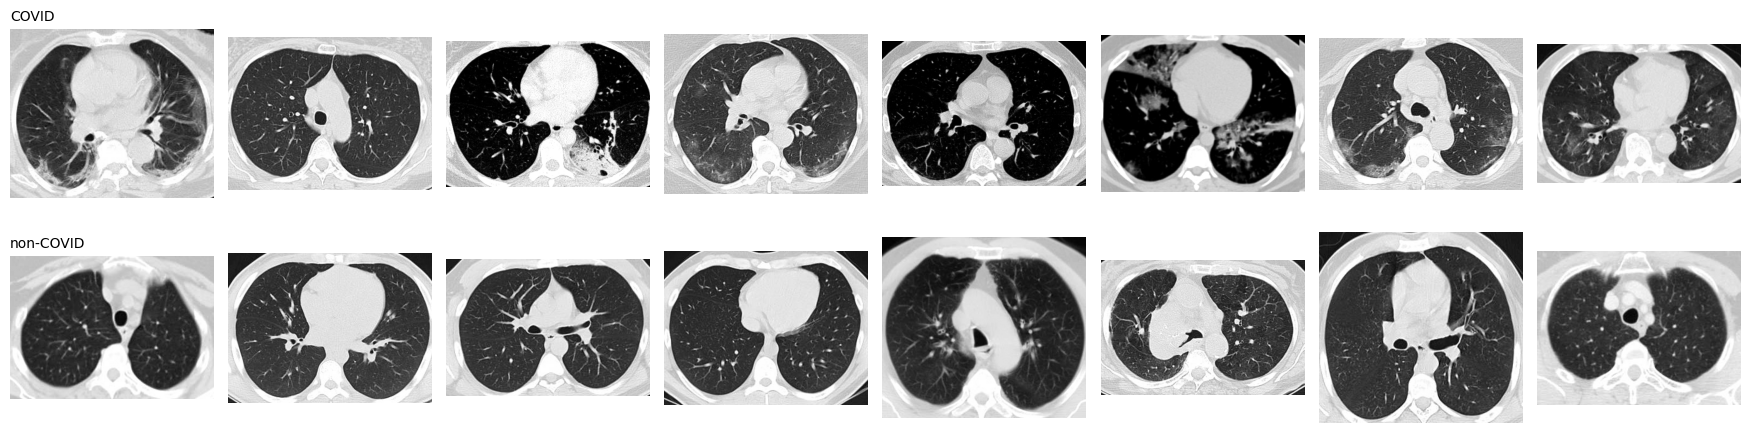

In [ ]:
n = 8
classes = sorted(df.cls.unique())
fig, axes = plt.subplots(len(classes), n, figsize=(2.2 * n, 2.4 * len(classes)))
axes = np.atleast_2d(axes)
for r, cls in enumerate(classes):
    sample = df[df.cls == cls].sample(min(n, (df.cls == cls).sum()), random_state=SEED)
    for c, (_, row) in enumerate(sample.iterrows()):
        axes[r, c].imshow(Image.open(row.path).convert("L"), cmap="gray")
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(cls, fontsize=10, loc="left")
plt.tight_layout()
plt.savefig("sample_grid.png", dpi=120)
print("\nSaved sample_grid.png")
 

Saved intensity_hist.png
Saved data_inventory.csv


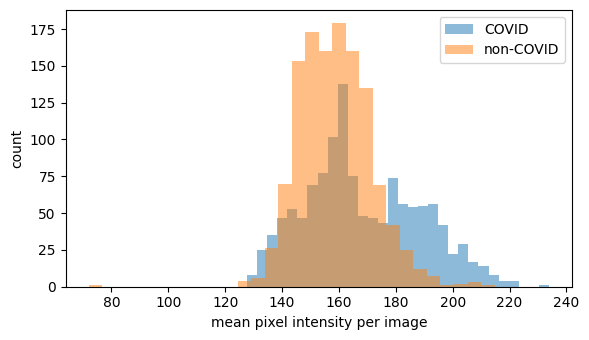

In [ ]:
plt.figure(figsize=(6, 3.5))
for cls in classes:
    plt.hist(df[df.cls == cls]["mean"], bins=30, alpha=0.5, label=cls)
plt.xlabel("mean pixel intensity per image"); plt.ylabel("count"); plt.legend()
plt.tight_layout(); plt.savefig("intensity_hist.png", dpi=120)
print("Saved intensity_hist.png")
 
df.drop(columns=["md5"]).to_csv("data_inventory.csv", index=False)
print("Saved data_inventory.csv")
 

In [ ]:
df = pd.read_csv("data_inventory.csv")
df = df[df.ok] if "ok" in df.columns else df
classes = sorted(df.cls.unique())
colors = dict(zip(classes, plt.cm.tab10.colors))
Path("plots").mkdir(exist_ok=True)

In [ ]:

def save_single(fn, name):
    fig, ax = plt.subplots(figsize=(6, 4))
    fn(ax)
    fig.tight_layout()
    fig.savefig(f"plots/{name}.png", dpi=130)
    plt.close(fig)

In [ ]:
def class_balance(ax):
    counts = df.cls.value_counts().reindex(classes)
    bars = ax.bar(counts.index, counts.values, color=[colors[c] for c in counts.index])
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), int(b.get_height()),
                ha="center", va="bottom", fontsize=9)
    ax.set_title("Class balance"); ax.set_ylabel("images")
 

In [ ]:
def intensity_hist(ax):
    for c in classes:
        ax.hist(df[df.cls == c]["mean"], bins=30, alpha=0.55, label=c, color=colors[c])
    ax.set_title("Mean pixel intensity per image")
    ax.set_xlabel("mean intensity (0-255)"); ax.set_ylabel("count"); ax.legend()

In [ ]:
def intensity_box(ax):
    ax.boxplot([df[df.cls == c]["mean"] for c in classes], labels=classes, showfliers=True)
    ax.set_title("Brightness by class"); ax.set_ylabel("mean intensity")

In [ ]:
def contrast_box(ax):
    ax.boxplot([df[df.cls == c]["std"] for c in classes], labels=classes, showfliers=True)
    ax.set_title("Contrast (pixel std) by class"); ax.set_ylabel("std")

In [ ]:
 
def size_scatter(ax):
    for c in classes:
        g = df[df.cls == c]
        ax.scatter(g.width, g.height, s=12, alpha=0.5, label=c, color=colors[c])
    ax.set_title("Image dimensions"); ax.set_xlabel("width (px)"); ax.set_ylabel("height (px)")
    ax.legend()
 

In [ ]:
def black_border(ax):
    for c in classes:
        ax.hist(df[df.cls == c]["black_frac"], bins=30, alpha=0.55, label=c, color=colors[c])
    ax.set_title("Fraction of near-black pixels (borders/padding)")
    ax.set_xlabel("black fraction"); ax.set_ylabel("count"); ax.legend()

In [ ]:
def aspect_ratio(ax):
    df["_ar"] = df.width / df.height
    for c in classes:
        ax.hist(df[df.cls == c]["_ar"], bins=30, alpha=0.55, label=c, color=colors[c])
    ax.set_title("Aspect ratio (width/height)"); ax.set_xlabel("ratio"); ax.legend()

In [ ]:
 
def mean_vs_std(ax):
    for c in classes:
        g = df[df.cls == c]
        ax.scatter(g["mean"], g["std"], s=10, alpha=0.4, label=c, color=colors[c])
    ax.set_title("Brightness vs contrast (class separation?)")
    ax.set_xlabel("mean"); ax.set_ylabel("std"); ax.legend()

In [ ]:
 
panels = [
    (class_balance, "class_balance"),
    (intensity_hist, "intensity_hist"),
    (intensity_box, "brightness_box"),
    (contrast_box, "contrast_box"),
    (size_scatter, "image_sizes"),
    (black_border, "black_border"),
    (aspect_ratio, "aspect_ratio"),
    (mean_vs_std, "mean_vs_std"),
]


C:\Users\krita\AppData\Local\Temp\ipykernel_3504\51594222.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([df[df.cls == c]["mean"] for c in classes], labels=classes, showfliers=True)
C:\Users\krita\AppData\Local\Temp\ipykernel_3504\1818623008.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([df[df.cls == c]["std"] for c in classes], labels=classes, showfliers=True)
C:\Users\krita\AppData\Local\Temp\ipykernel_3504\51594222.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([df[df.cls == c]["mean"] for c in classes], labels=classes, showfliers=True)
C:\Users\krita\AppData\Local\T

Saved data_overview.png and individual plots in plots/


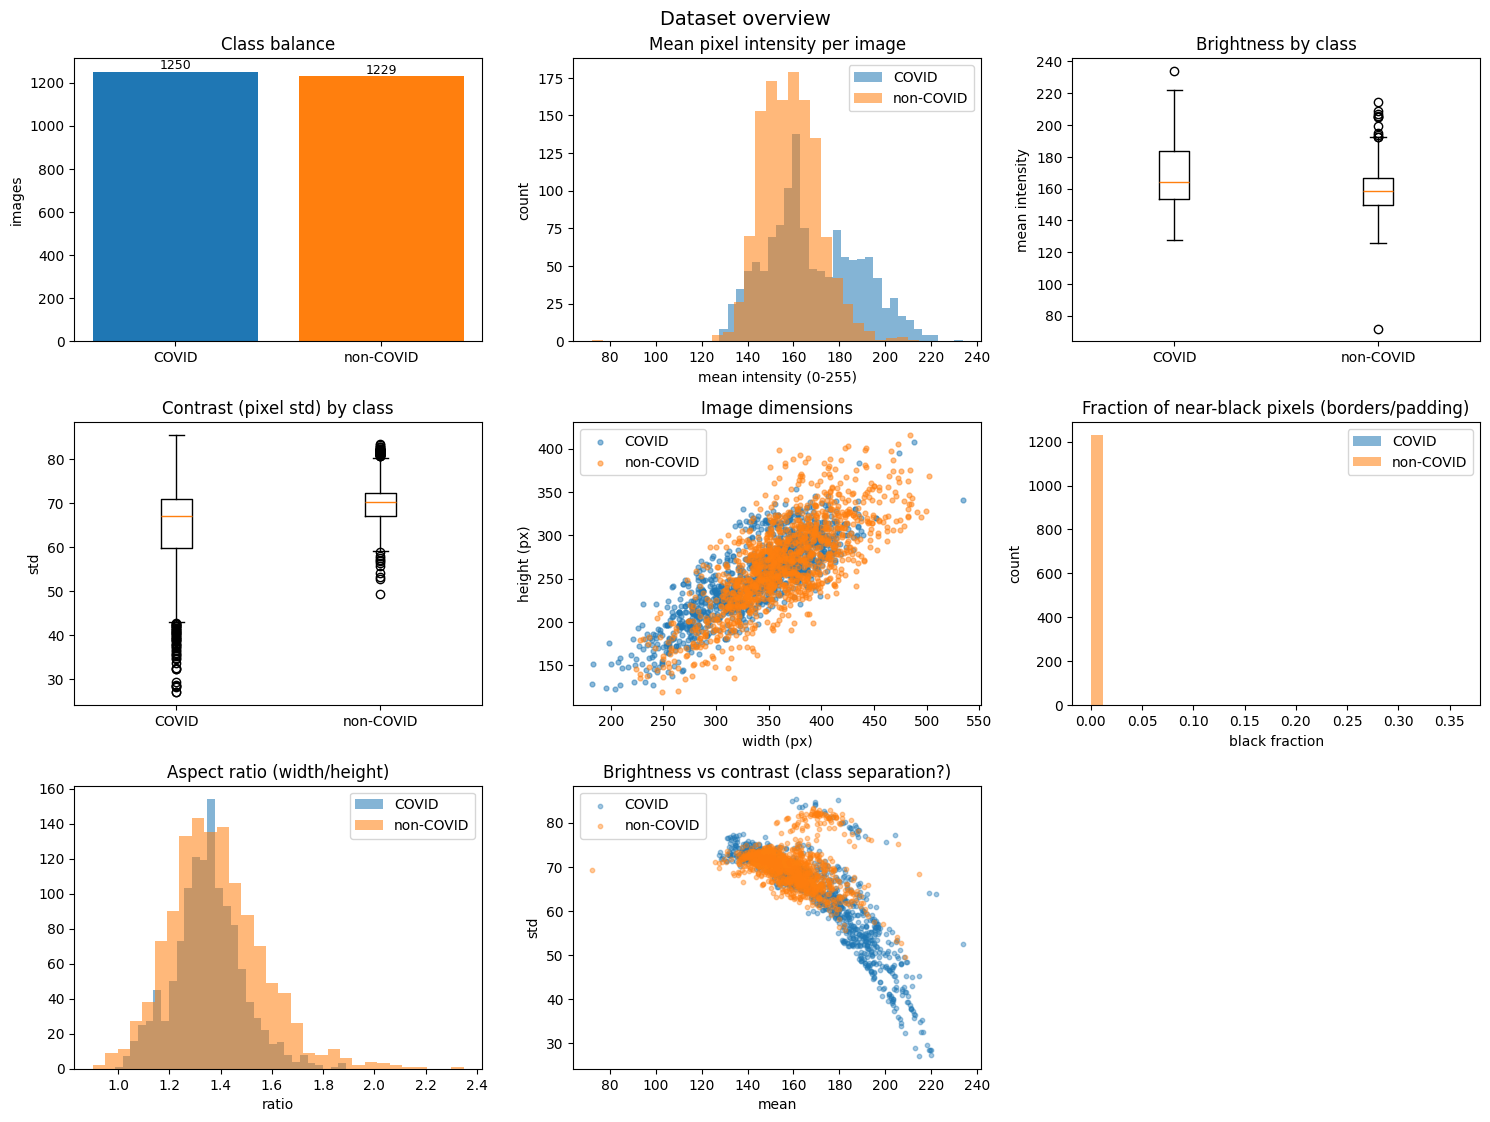

In [ ]:
cols = 3
rows = int(np.ceil(len(panels) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.8 * rows))
axes = axes.ravel()
for ax, (fn, name) in zip(axes, panels):
    fn(ax)
for ax in axes[len(panels):]:
    ax.axis("off")
fig.suptitle("Dataset overview", fontsize=14)
fig.tight_layout()
fig.savefig("data_overview.png", dpi=130)
 
# individual files
for fn, name in panels:
    save_single(fn, name)
 
print("Saved data_overview.png and individual plots in plots/")
plt.show()

In [ ]:
def build_dataframe(data_dir: Path) -> pd.DataFrame:
    rows = []
    for cls_name, label in CLASSES.items():
        for p in (data_dir / cls_name).glob("*"):
            if p.suffix.lower() not in {".png", ".jpg", ".jpeg"}:
                continue
            m = re.match(r"(.+?)[_\-]?\d+$", p.stem)
            patient = f"{cls_name}_{m.group(1) if m else p.stem}"
            rows.append({"path": str(p), "label": label, "patient_id": patient})
    df = pd.DataFrame(rows)
    print(f"{len(df)} images, {df.patient_id.nunique()} patient groups")
    return df

In [ ]:
def patient_splits(df, n_splits=5, val_size=0.15):
    splitter = GroupKFold(n_splits=n_splits)
    inner_val_size = val_size / (1 - 1 / n_splits)

    for fold, (trainval_idx, test_idx) in enumerate(
        splitter.split(df, groups=df["patient_id"]), start=1
    ):
        trainval = df.iloc[trainval_idx]
        test = df.iloc[test_idx]

        val_splitter = GroupShuffleSplit(
            n_splits=1,
            test_size=inner_val_size,
            random_state=SEED + fold,
        )
        train_idx, val_idx = next(
            val_splitter.split(trainval, groups=trainval["patient_id"])
        )

        train = trainval.iloc[train_idx]
        val = trainval.iloc[val_idx]

        yield train, val, test

In [ ]:
class CTDataset(Dataset):
    def __init__(self, df, transform):
        self.df, self.transform = df.reset_index(drop=True), transform
 
    def __len__(self):
        return len(self.df)
 
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row.path).convert("RGB")
        return self.transform(img), to.tensor(row.label, dtype=to.float32)
 
 
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    norm,
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    norm,
])

def build_model():
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, 1))
    return model.to(DEVICE)

@to.no_grad()
def predict(model, loader):
    model.eval()
    probs, labels = [], []
    for x, y in loader:
        logits = model(x.to(DEVICE)).squeeze(1)
        probs.extend(to.sigmoid(logits).cpu().numpy())
        labels.extend(y.numpy())
    return np.array(probs), np.array(labels)
 
 
def metrics(probs, labels, thr=0.5):
    preds = (probs >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
    return {
        "auc": roc_auc_score(labels, probs),
        "sensitivity": tp / (tp + fn + 1e-9),   # recall on COVID
        "specificity": tn / (tn + fp + 1e-9),
        "accuracy": (tp + tn) / len(labels),
        "confusion": [[int(tn), int(fp)], [int(fn), int(tp)]],
    }
 
 
def patient_bootstrap_auc_ci(oof_df, n_bootstrap=2000):
    patient_rows = list(oof_df.groupby("patient_id", sort=False).indices.values())
    labels = oof_df["label"].to_numpy()
    probs = oof_df["prob"].to_numpy()
    rng = np.random.default_rng(SEED)
    bootstrap_aucs = []
 
    for _ in range(n_bootstrap):
        sampled_groups = rng.integers(0, len(patient_rows), size=len(patient_rows))
        row_indices = np.concatenate([patient_rows[i] for i in sampled_groups])
        sample_labels = labels[row_indices]
        if np.unique(sample_labels).size < 2:
            continue
        bootstrap_aucs.append(roc_auc_score(sample_labels, probs[row_indices]))
 
    if len(bootstrap_aucs) < 100:
        raise ValueError("Too few valid patient-bootstrap samples to estimate an AUC interval")
    return np.percentile(bootstrap_aucs, [2.5, 97.5])
 
 
def train(model, train_loader, val_loader, pos_weight, checkpoint_path="best_model.pt"):
    criterion = nn.BCEWithLogitsLoss(pos_weight=to.tensor([pos_weight]).to(DEVICE))
    optimizer = to.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    scheduler = to.optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS)
 
    print(f"Training on {DEVICE} | {len(train_loader)} batches/epoch | "
          f"max {EPOCHS} epochs | early-stop patience {PATIENCE}", flush=True)
 
    best_auc, bad_epochs = 0.0, 0
    run_start = time.time()
    epoch_times = []
 
    for epoch in range(EPOCHS):
        ep_start = time.time()
        model.train()
        running_loss, correct, seen = 0.0, 0, 0
 
        # live progress bar: updates after every batch
        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [train]", leave=False)
        for x, y in pbar:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            logits = model(x).squeeze(1)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
 
            running_loss += loss.item() * len(x)
            correct += ((logits > 0).float() == y).sum().item()
            seen += len(x)
            pbar.set_postfix(loss=f"{running_loss/seen:.4f}", acc=f"{correct/seen:.3f}")
        scheduler.step()
 
        # validation
        print(f"Epoch {epoch+1}/{EPOCHS}: validating...", flush=True)
        probs, labels = predict(model, val_loader)
        m = metrics(probs, labels)
 
        # timing + ETA
        epoch_times.append(time.time() - ep_start)
        avg = sum(epoch_times) / len(epoch_times)
        eta_min = avg * (EPOCHS - epoch - 1) / 60
 
        improved = m["auc"] > best_auc
        print(
            f"Epoch {epoch+1:02d}/{EPOCHS} | "
            f"train loss {running_loss/seen:.4f} acc {correct/seen:.3f} | "
            f"val AUC {m['auc']:.3f} sens {m['sensitivity']:.3f} "
            f"spec {m['specificity']:.3f} acc {m['accuracy']:.3f} | "
            f"lr {scheduler.get_last_lr()[0]:.2e} | "
            f"{epoch_times[-1]:.0f}s (ETA ~{eta_min:.1f} min)"
            f"{'  * best, saved' if improved else ''}",
            flush=True,
        )
 
        if improved:
            best_auc, bad_epochs = m["auc"], 0
            to.save(model.state_dict(), checkpoint_path)
        else:
            bad_epochs += 1
            print(f"   no improvement ({bad_epochs}/{PATIENCE})", flush=True)
            if bad_epochs >= PATIENCE:
                print("   early stopping triggered", flush=True)
                break
 
    print(f"Finished in {(time.time()-run_start)/60:.1f} min | best val AUC {best_auc:.3f}",
          flush=True)
    model.load_state_dict(to.load(checkpoint_path, map_location=DEVICE))
    return model
def grad_cam(model, img_tensor):
    """Heatmap from the last ResNet conv block. img_tensor: (3,H,W)."""
    model.eval()
    feats, grads = [], []
    layer = model.layer4[-1]
    h1 = layer.register_forward_hook(lambda m, i, o: feats.append(o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: grads.append(go[0]))
 
    x = img_tensor.unsqueeze(0).to(DEVICE).requires_grad_(True)
    model.zero_grad()
    model(x).squeeze().backward()
    h1.remove(); h2.remove()
 
    weights = grads[0].mean(dim=(2, 3), keepdim=True)
    cam = to.relu((weights * feats[0]).sum(1)).squeeze().detach().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-9)
    return cam
 
def save_gradcam_examples(model, df, n=6, out="gradcam.png"):
    import matplotlib.pyplot as plt
    import torch.nn.functional as F
 
    sample = df.sample(n, random_state=SEED)
    fig, axes = plt.subplots(2, n, figsize=(3 * n, 6))
    for i, (_, row) in enumerate(sample.iterrows()):
        img = Image.open(row.path).convert("RGB")
        t = eval_tf(img)
        cam = grad_cam(model, t)
        cam = F.interpolate(to.tensor(cam)[None, None], size=(IMG_SIZE, IMG_SIZE),
                            mode="bilinear")[0, 0].numpy()
        base = img.resize((IMG_SIZE, IMG_SIZE))
        axes[0, i].imshow(base); axes[0, i].axis("off")
        axes[0, i].set_title(f"label={row.label}")
        axes[1, i].imshow(base); axes[1, i].imshow(cam, cmap="jet", alpha=0.4)
        axes[1, i].axis("off")
    plt.tight_layout(); plt.savefig(out, dpi=120)
    print(f"saved {out} (check the model looks at lungs, not corners/text)")
 

In [ ]:
if __name__ == "__main__":
    print("device:", DEVICE, "| cuda available:", torch.cuda.is_available(), flush=True)
    df = build_dataframe(DATA_DIR)
    n_splits = 5
    fold_aucs, oof_predictions = [], []
    last_model, last_test_df, last_fold = None, None, None
    script_start = time.time()
 
    for fold, (train_df, val_df, test_df) in enumerate(
        patient_splits(df, n_splits=n_splits, val_size=0.15), start=1
    ):
        print(f"\n{'='*20} Fold {fold}/{n_splits} {'='*20}", flush=True)
        print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)}", flush=True)
        print(f"class counts (train): {train_df.label.value_counts().to_dict()}", flush=True)
        torch.manual_seed(SEED + fold)
        np.random.seed(SEED + fold)
 
        # num_workers=0 avoids silent hangs on Windows
        train_loader = DataLoader(
            CTDataset(train_df, train_tf), BATCH_SIZE, shuffle=True, num_workers=0
        )
        val_loader = DataLoader(CTDataset(val_df, eval_tf), BATCH_SIZE, num_workers=0)
        test_loader = DataLoader(CTDataset(test_df, eval_tf), BATCH_SIZE, num_workers=0)
 
        n_pos = (train_df.label == 1).sum()
        n_neg = (train_df.label == 0).sum()
        print("Building model...", flush=True)
        model = train(
            build_model(), train_loader, val_loader,
            pos_weight=n_neg / max(n_pos, 1),
            checkpoint_path=f"best_model_fold_{fold}.pt",
        )
 
        print(f"Fold {fold}: evaluating on test set...", flush=True)
        probs, labels = predict(model, test_loader)
        fold_metrics = metrics(probs, labels)
        fold_aucs.append(fold_metrics["auc"])
        oof_predictions.append(pd.DataFrame({
            "patient_id": test_df["patient_id"].to_numpy(),
            "label": labels.astype(int),
            "prob": probs,
        }))
        print(f"Fold {fold} TEST: AUC {fold_metrics['auc']:.3f} | "
              f"sens {fold_metrics['sensitivity']:.3f} | "
              f"spec {fold_metrics['specificity']:.3f} | "
              f"acc {fold_metrics['accuracy']:.3f}", flush=True)
        print(f"Fold {fold} confusion [[TN, FP], [FN, TP]]: {fold_metrics['confusion']}",
              flush=True)
 
        done = time.time() - script_start
        remaining = done / fold * (n_splits - fold)
        print(f"Elapsed {done/60:.1f} min | est. remaining ~{remaining/60:.1f} min", flush=True)
        last_model, last_test_df, last_fold = model, test_df, fold
 
    oof_df = pd.concat(oof_predictions, ignore_index=True)
    fold_mean = np.mean(fold_aucs)
    fold_std = np.std(fold_aucs, ddof=1)
    ci_low, ci_high = patient_bootstrap_auc_ci(oof_df)
    print(f"\nPer-fold AUCs: {[round(a, 3) for a in fold_aucs]}")
    print(f"Fold test AUC: {fold_mean:.3f} +/- {fold_std:.3f} (mean +/- SD)")
    print(f"Pooled out-of-fold AUC: {roc_auc_score(oof_df.label, oof_df.prob):.3f}")
    print(f"95% patient-bootstrap CI: [{ci_low:.3f}, {ci_high:.3f}]")
 
    save_gradcam_examples(
        last_model, last_test_df, out=f"gradcam_fold_{last_fold}.png"
    )
    print(f"\nAll done in {(time.time()-script_start)/60:.1f} min", flush=True)

2481 images, 2481 patient groups

=== Fold 1/5 ===
train 1612 | val 372 | test 497


epoch 1:   0%|          | 0/51 [00:00<?, ?it/s]

: 

: 